# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

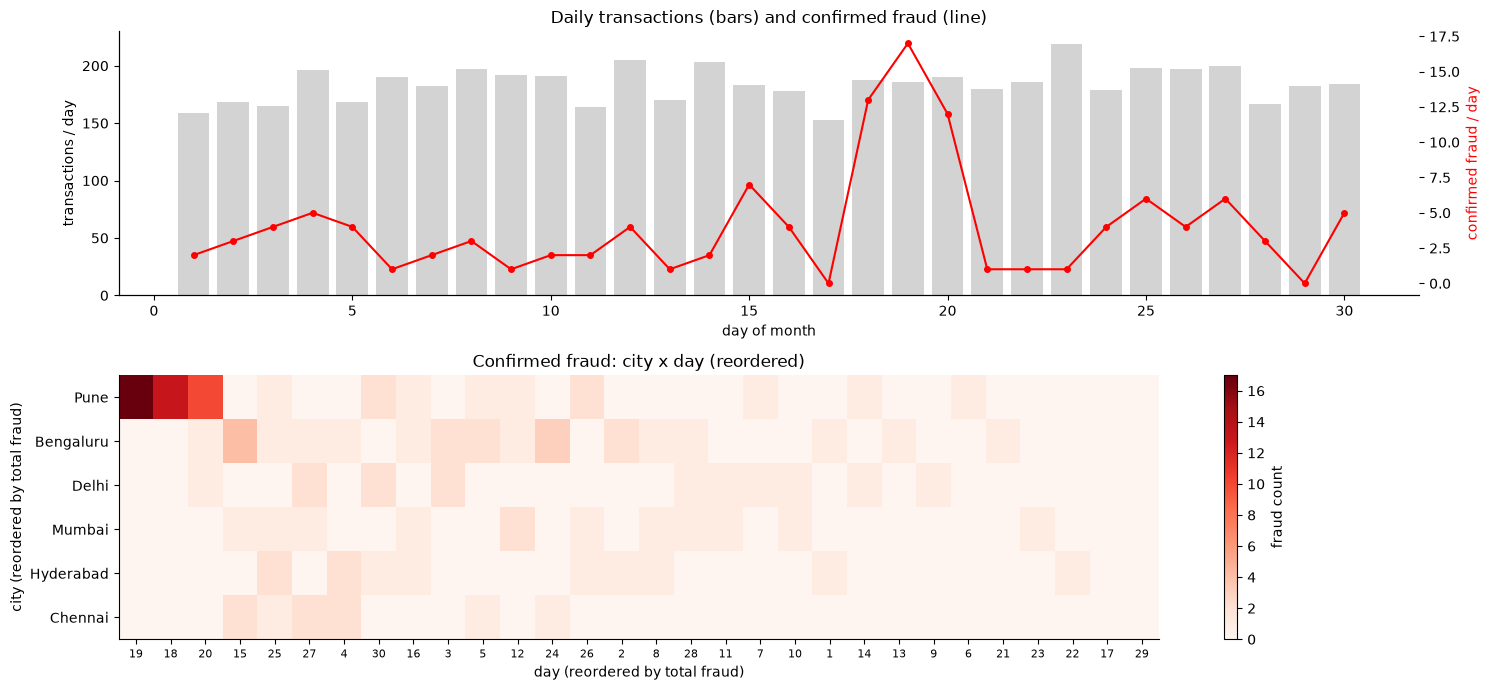

city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily = tx.groupby("day").agg(n=("txn_id", "size"), fraud=("is_fraud", "sum"))
axes[0].bar(daily.index, daily.n, color="lightgrey", label="all transactions")
axes[0].set(xlabel="day of month", ylabel="transactions / day", title="Daily transactions (bars) and confirmed fraud (line)")
ax2 = axes[0].twinx()
ax2.plot(daily.index, daily.fraud, "-o", color="red", ms=4, label="confirmed fraud")
ax2.set_ylabel("confirmed fraud / day", color="red")

# TODO 2
heat = (tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
        .reindex(index=tx.city.unique(), columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index, heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns, fontsize=8)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set(xlabel="day (reordered by total fraud)", ylabel="city (reordered by total fraud)", title="Confirmed fraud: city x day (reordered)")
plt.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3
print(heat.stack().sort_values(ascending=False).head(5))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ The overview showed a burst of fraud concentrated in Pune on days 18–20 — a spatio-temporal cluster that a score-sorted alert list (one row at a time) can't reveal. I found it by reordering the city × day matrix so the dense block popped out (matrix reordering / seriation).

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

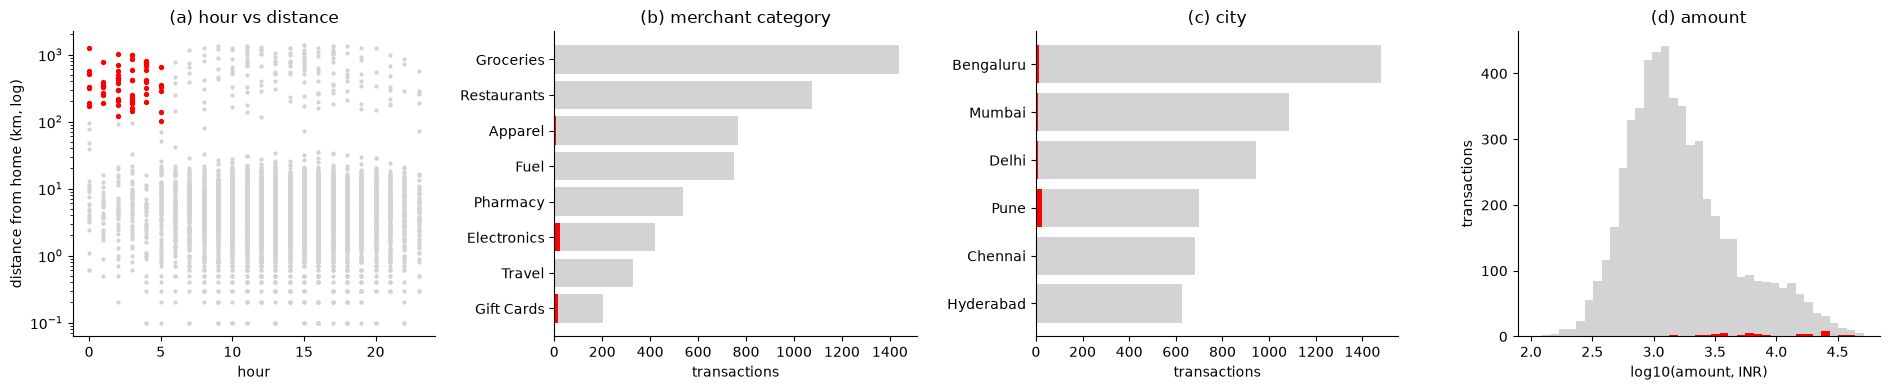

brushed: 61 transactions
fraud rate in brush: 86.9% vs overall 2.2%
share of all fraud captured by the brush: 44.2%


In [4]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
GREY_, RED_ = "lightgrey", "red"
axes[0].scatter(tx.hour, tx.distance_from_home_km, s=4, c=GREY_)
axes[0].scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=8, c=RED_)
axes[0].set(yscale="log", xlabel="hour", ylabel="distance from home (km, log)", title="(a) hour vs distance")

for ax, col, title in [(axes[1], "merchant_category", "(b) merchant category"), (axes[2], "city", "(c) city")]:
    allc = tx[col].value_counts()
    brc = tx.loc[brush, col].value_counts().reindex(allc.index, fill_value=0)
    ax.barh(allc.index, allc.values, color=GREY_)
    ax.barh(brc.index, brc.values, color=RED_)
    ax.invert_yaxis(); ax.set(xlabel="transactions", title=title)

la = np.log10(tx.amount_inr)
bins = np.linspace(la.min(), la.max(), 40)
axes[3].hist(la, bins=bins, color=GREY_)
axes[3].hist(la[brush], bins=bins, color=RED_)
axes[3].set(xlabel="log10(amount, INR)", ylabel="transactions", title="(d) amount")

plt.tight_layout(); plt.show()

# TODO 3
print(f"brushed: {brush.sum()} transactions")
print(f"fraud rate in brush: {tx.is_fraud[brush].mean():.1%} vs overall {tx.is_fraud.mean():.1%}")
print(f"share of all fraud captured by the brush: {tx.is_fraud[brush].sum() / tx.is_fraud.sum():.1%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ The brush has ~87% fraud rate but captures only ~44% of all fraud, so the rule alone would miss more than half the cases. The city and merchant-category views hinted that the rest is concentrated in Pune and in Electronics / Gift Cards.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [5]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / best_s * len(big)

# TODO 3
t_50m = per_item_us * 50_000_000 / 1e6
skip_pct = max(0.0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 9.2 ms -> 0.0092 us/row -> max 10,905,171 rows in 0.1 s
50M rows -> 0.46 s; must skip 78.2% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ Pre-aggregation / binning (e.g. counts per score × amount bin) or sampling, so the slider queries a small summary instead of 50M rows. The analyst loses exact individual-transaction detail (and rare outliers in sampling) until they drill down.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,f1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532


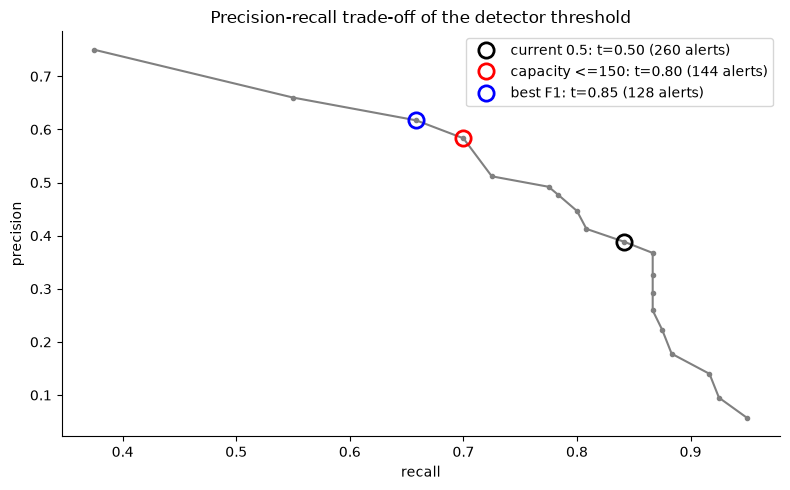

Recommendation: raise the threshold from 0.50 to 0.80 -> 144 alerts/month (within 150), precision 58%, recall 70% (best-F1 threshold is 0.85).


In [6]:
rows = []
# TODO 1
n_fraud = tx.is_fraud.sum()
for t in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flag = tx.detector_score >= t
    tp = int((flag & (tx.is_fraud == 1)).sum()); fp = int((flag & (tx.is_fraud == 0)).sum()); fn = int(n_fraud - tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / n_fraud
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({"threshold": t, "alerts": tp + fp, "TP": tp, "FP": fp, "FN": fn, "precision": precision, "recall": recall, "f1": f1})

pr = pd.DataFrame(rows)

# TODO 2
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.f1.idxmax()]
current = pr.loc[np.isclose(pr.threshold, 0.5)].iloc[0]
display(pr.round(3))

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="grey", ms=3)
for r, name, c in [(current, "current 0.5", "black"), (capacity_choice, "capacity <=150", "red"), (best_f1, "best F1", "blue")]:
    ax.plot(r.recall, r.precision, "o", ms=11, mfc="none", mec=c, mew=2, label=f"{name}: t={r.threshold:.2f} ({r.alerts:.0f} alerts)")
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall trade-off of the detector threshold")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: raise the threshold from 0.50 to {capacity_choice.threshold:.2f} -> {capacity_choice.alerts:.0f} alerts/month "
      f"(within 150), precision {capacity_choice.precision:.0%}, recall {capacity_choice.recall:.0%} "
      f"(best-F1 threshold is {best_f1.threshold:.2f}).")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The Head of Fraud Ops should decide, because the trade-off depends on team capacity and the cost of missed fraud vs wasted reviews, which the model doesn't know. Visual analytics keeps a human in the loop so domain knowledge and accountability steer the parameter, with the PR curve making the trade-off visible.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [7]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                 color_discrete_map={"confirmed fraud": "red", "legitimate": "lightgrey"},
                 hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
                 title=f"{len(flagged)} transactions with detector score >= 0.3 (box/lasso-select to inspect)")
fig.update_layout(dragmode="select")
fig.show()

# TODO 2
agg = (tx.groupby(["city", "merchant_category"])
         .agg(transactions=("txn_id", "size"), fraud_rate=("is_fraud", "mean")).reset_index())
fig2 = px.sunburst(agg, path=["city", "merchant_category"], values="transactions", color="fraud_rate",
                   color_continuous_scale="Reds", title="Drill down: city -> merchant category (colour = fraud rate)")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ Tooltips show one point at a time, so getting an overview of 400 cases means hovering hundreds of times and remembering them. The overview views — the reordered heatmap / sunburst (or linked views) — show the whole set at once.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

fraud rate inside window 37.4% vs outside 1.5%  (chi2 = 619.3, p = 1.06e-136)
Pune, days 18-20            37.38
Pune, other days             1.85
other cities, days 18-20     0.44
rest                         1.54
dtype: float64


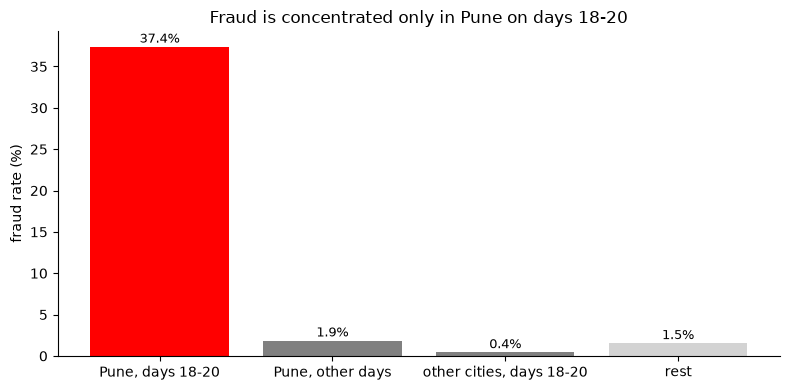

Verdict: SUPPORTED - fraud rate 37% in Pune days 18-20 vs 1.9% in Pune on other days and 0.4% in other cities on those days (p = 1.1e-136); escalate as a likely localized fraud ring.


In [8]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# H1: confirmed fraud is concentrated in Pune on days 18-20 (a fraud ring), not spread across cities/days.
ring_days = tx.day.between(18, 20)
in_window = (tx.city == "Pune") & ring_days

# TODO 2
rate_in, rate_out = tx.is_fraud[in_window].mean(), tx.is_fraud[~in_window].mean()
chi2, p, _, _ = chi2_contingency(pd.crosstab(in_window, tx.is_fraud))
print(f"fraud rate inside window {rate_in:.1%} vs outside {rate_out:.1%}  (chi2 = {chi2:.1f}, p = {p:.2e})")

# TODO 3
same_city_other_days = (tx.city == "Pune") & ~ring_days
other_cities_same_days = (tx.city != "Pune") & ring_days
rest = ~(in_window | same_city_other_days | other_cities_same_days)
groups = {"Pune, days 18-20": in_window, "Pune, other days": same_city_other_days,
          "other cities, days 18-20": other_cities_same_days, "rest": rest}
rates = pd.Series({k: tx.is_fraud[m].mean() * 100 for k, m in groups.items()})
print(rates.round(2))

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(rates.index, rates.values, color=["red", "grey", "grey", "lightgrey"])
for i, v in enumerate(rates.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.set(ylabel="fraud rate (%)", title="Fraud is concentrated only in Pune on days 18-20")
plt.tight_layout(); plt.show()

# TODO 5
print(f"Verdict: SUPPORTED - fraud rate {rate_in:.0%} in Pune days 18-20 vs {rates['Pune, other days']:.1f}% in Pune on other days "
      f"and {rates['other cities, days 18-20']:.1f}% in other cities on those days (p = {p:.1e}); escalate as a likely localized fraud ring.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ Search (a), the same city on other days — if Pune had high fraud every day it would mean Pune is just generally riskier (e.g. a weak merchant or local data issue), not a short-lived ring. Search (b) ruling out other cities also guards against a platform-wide event on those days.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_ Last month had 120 confirmed frauds in 5,520 transactions (2.2%), a third of them (40) from a fraud ring in Pune on days 18–20. Raise the alert threshold from 0.5 to 0.8: about 144 alerts/month fits the 150-case capacity at ~58% precision and ~70% recall (close to best F1 at 0.85), and the Head of Fraud Ops should own that trade-off. Build the overview-first city × day heatmap with linked brushing first, so investigators see clusters like Pune before triaging individual alerts, keeping filters under the 0.1 s budget via pre-aggregation. Add a relevance-feedback loop where investigators' confirmed labels are fed back to retrain the detector.